In [9]:
# Import the main libraries used for numerical analysis, data manipulation, plotting, PCA, scaling, and clustering.
# import some packages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from ISLP import load_data
from sklearn.cluster import \
(KMeans ,
AgglomerativeClustering )
from scipy.cluster.hierarchy import \
(dendrogram ,
cut_tree)
from ISLP.cluster import compute_linkage

# 12.5.1 Principal Components Analysis

In [12]:
# Load the USArrests dataset and display the first few observations to understand its structure.
## perform USArrests dataset

USArrests = get_rdataset('USArrests').data
USArrests

,Murder,Assault,UrbanPop,Rape
rownames,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6
Colorado,7.9,204,78,38.7
Connecticut,3.3,110,77,11.1
Delaware,5.9,238,72,15.8
Florida,15.4,335,80,31.9


In [20]:
# Display the names of all columns/variables in the USArrests dataset.
## retriev columns of a dataset

USArrests.columns

Index(['Murder', 'Assault', 'UrbanPop', 'Rape'], dtype='object')

In [21]:
# Calculate the mean value of each variable in the dataset.
## Examin mean for each

USArrests.mean ()

Murder        7.788
Assault     170.760
UrbanPop     65.540
Rape         21.232
dtype: float64

In [22]:
# Calculate the variance of each variable to examine the spread of the data.
## examin variance for each 
USArrests.var()

Murder        18.970465
Assault     6945.165714
UrbanPop     209.518776
Rape          87.729159
dtype: float64

In [23]:
# Standardize the variables so that they have mean 0 and standard deviation 1 before PCA.
## combine the methods
scaler = StandardScaler(with_std=True ,
with_mean=True)
USArrests_scaled = scaler.fit_transform(USArrests)

In [24]:
# Create a PCA object without specifying the number of components, so all components are retained.
pcaUS = PCA()

In [25]:
# Fit the PCA model to the standardized USArrests data.
pcaUS.fit(USArrests_scaled)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [38]:
# Display the mean vector estimated by the PCA model.
pcaUS.mean_

array([-7.10542736e-17,  1.38777878e-16, -4.39648318e-16,  8.59312621e-16])

In [40]:
# Transform the standardized observations into their principal-component scores.
scores = pcaUS.transform(USArrests_scaled)

In [42]:
# Display the PCA loading vectors, showing how the original variables contribute to each component.
## principal componet load
pcaUS.components_

array([[ 0.53589947,  0.58318363,  0.27819087,  0.54343209],
       [-0.41818087, -0.1879856 ,  0.87280619,  0.16731864],
       [-0.34123273, -0.26814843, -0.37801579,  0.81777791],
       [-0.6492278 ,  0.74340748, -0.13387773, -0.08902432]])

Text(0.5434320914456824, 0.16731863540174616, 'Rape')

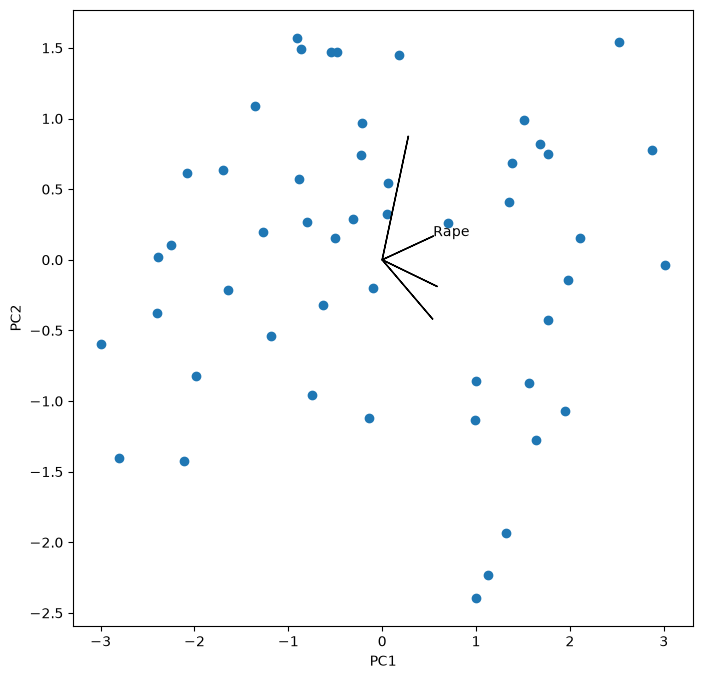

In [44]:
# Create a biplot to visualize observations and variable directions using the first two principal components.
#biplot
i, j = 0, 1 # which components
fig , ax = plt.subplots (1, 1, figsize =(8, 8))
ax.scatter(scores [:,0], scores [: ,1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pcaUS.components_.shape [1]):
    ax.arrow(0, 0, pcaUS.components_[i,k], pcaUS.components_[j,k])
ax.text(pcaUS.components_[i,k],
pcaUS.components_[j,k],
USArrests.columns[k])

Text(1.0868641828913648, -0.3346372708034923, 'Rape')

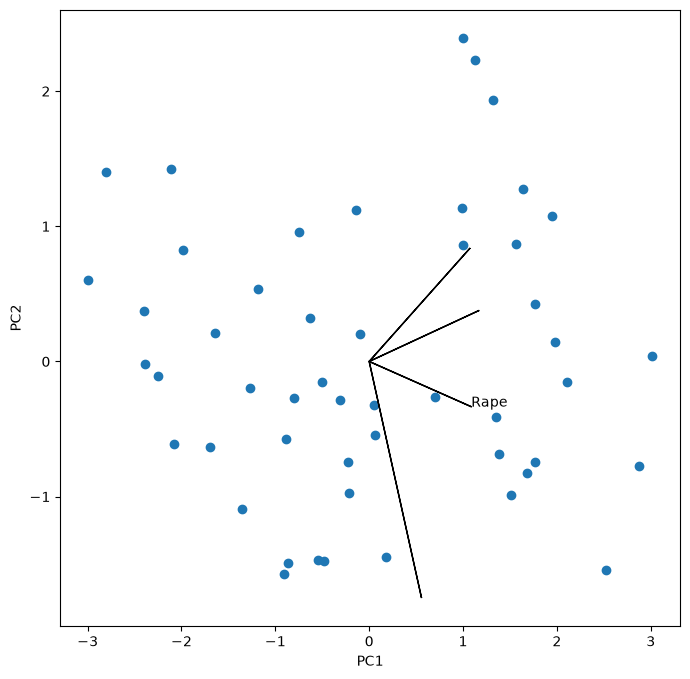

In [46]:
# Adjust the scale and direction of the second principal component for clearer biplot visualization.
scale_arrow = s_ = 2
scores [:,1] *= -1
pcaUS.components_ [1] *= -1 # flip the y-axis
fig , ax = plt.subplots (1, 1, figsize =(8, 8))
ax.scatter(scores [:,0], scores [: ,1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pcaUS.components_.shape [1]):
    ax.arrow(0, 0, s_*pcaUS.components_[i,k], s_*pcaUS.components_[
j,k])
ax.text(s_*pcaUS.components_[i,k],
s_*pcaUS.components_[j,k],
USArrests.columns[k])


In [48]:
# Calculate the standard deviation of the scores for each principal component.
##The standard deviations of the principal component scores
scores.std(0, ddof =1)

array([1.5908673 , 1.00496987, 0.6031915 , 0.4206774 ])

In [50]:
# Display the variance explained by each principal component.
pcaUS.explained_variance_

array([2.53085875, 1.00996444, 0.36383998, 0.17696948])

In [52]:
# Display the proportion of total variance explained by each principal component.
pcaUS.explained_variance_ratio_

array([0.62006039, 0.24744129, 0.0891408 , 0.04335752])

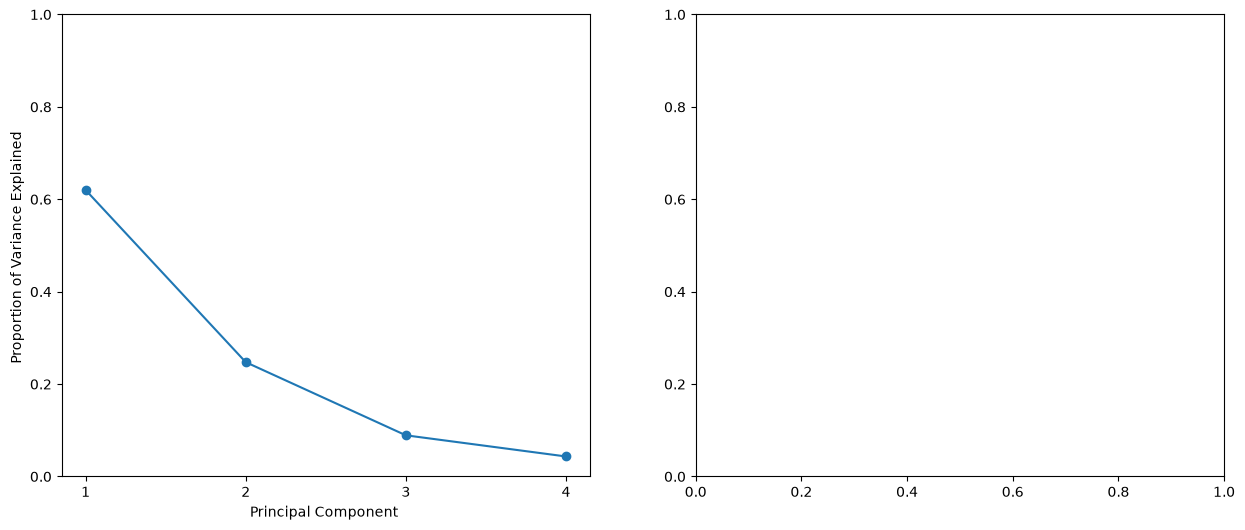

In [54]:
# Plot the proportion of variance explained by each principal component.

fig , axes = plt.subplots (1, 2, figsize =(15, 6))
ticks = np.arange(pcaUS.n_components_)+1
ax = axes [0]
ax.plot(ticks ,
pcaUS.explained_variance_ratio_ ,
marker='o')
ax.set_xlabel('Principal Component ');
ax.set_ylabel('Proportion of Variance Explained ')
ax.set_ylim ([0 ,1])
ax.set_xticks(ticks)

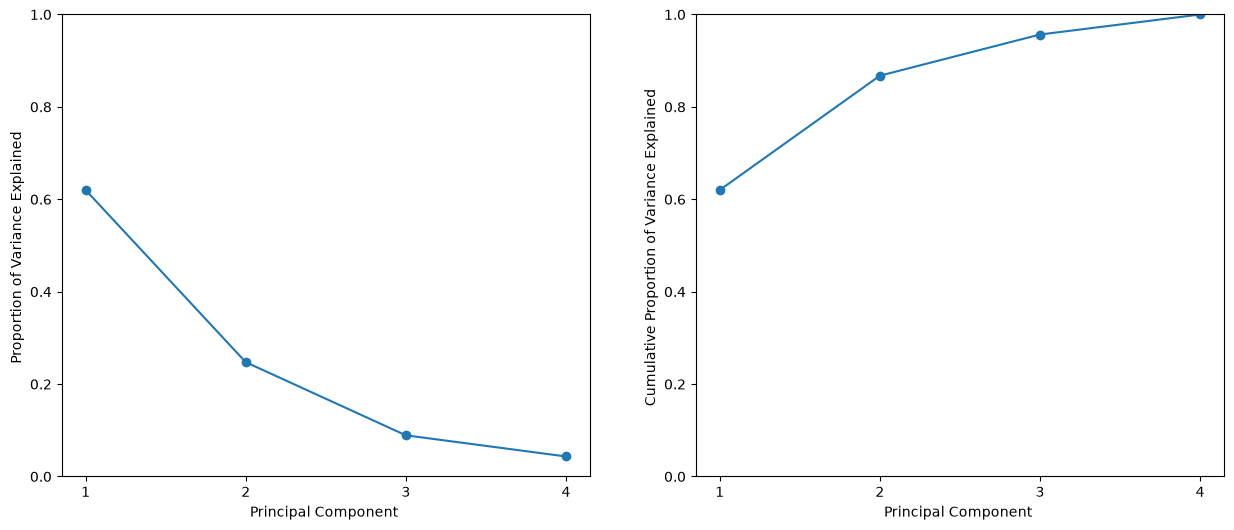

In [56]:
# Plot the cumulative proportion of variance explained to see how many components are needed.
ax = axes [1]
ax.plot(ticks ,
pcaUS. explained_variance_ratio_ .cumsum (),
marker='o')
ax.set_xlabel('Principal Component ')
ax.set_ylabel('Cumulative Proportion of Variance Explained ')
ax.set_ylim ([0, 1])
ax.set_xticks(ticks)
fig

In [58]:
# Demonstrate cumulative sums, which are useful for understanding cumulative explained variance.
a = np.array ([1,2,8,-3])
np.cumsum(a)

array([ 1,  3, 11,  8])

# Matrix Completion

In [61]:
# Apply singular value decomposition (SVD) to the standardized data as an alternative representation of PCA.
X = USArrests_scaled
U, D, V = np.linalg.svd(X, full_matrices=False)
U.shape , D.shape , V.shape

((50, 4), (4,), (4, 4))

In [63]:
# Display the right singular vectors obtained from the SVD.
V

array([[-0.53589947, -0.58318363, -0.27819087, -0.54343209],
       [-0.41818087, -0.1879856 ,  0.87280619,  0.16731864],
       [ 0.34123273,  0.26814843,  0.37801579, -0.81777791],
       [ 0.6492278 , -0.74340748,  0.13387773,  0.08902432]])

In [65]:
# Display the PCA component loading vectors for comparison with the SVD results.
pcaUS.components_

array([[ 0.53589947,  0.58318363,  0.27819087,  0.54343209],
       [ 0.41818087,  0.1879856 , -0.87280619, -0.16731864],
       [-0.34123273, -0.26814843, -0.37801579,  0.81777791],
       [-0.6492278 ,  0.74340748, -0.13387773, -0.08902432]])

In [67]:
# Display the first three rows of the PCA scores calculated from the SVD components.
(U * D[None ,:]) [:3]

array([[-0.98556588, -1.13339238,  0.44426879,  0.15626714],
       [-1.95013775, -1.07321326, -2.04000333, -0.43858344],
       [-1.76316354,  0.74595678, -0.05478082, -0.83465292]])

In [69]:
# Display the first three principal-component scores calculated earlier using PCA.
scores [:3]

array([[ 0.98556588,  1.13339238, -0.44426879, -0.15626714],
       [ 1.95013775,  1.07321326,  2.04000333,  0.43858344],
       [ 1.76316354, -0.74595678,  0.05478082,  0.83465292]])

In [71]:
# Randomly select observations and variables that will be treated as missing values for the matrix-completion exercise.
n_omit = 20
np.random.seed (15)
r_idx = np.random.choice(np.arange(X.shape [0]) ,
n_omit ,
replace=False)
c_idx = np.random.choice(np.arange(X.shape [1]) ,
n_omit ,
replace=True)
Xna = X.copy ()
Xna[r_idx , c_idx] = np.nan

In [73]:
# Define a function that approximates a matrix using its first M singular components (low-rank approximation).
def low_rank(X, M=1):
    U, D, V = np.linalg.svd(X)
    L = U[:,:M] * D[None ,:M]
    return L.dot(V[:M])


In [75]:
# Create the initial incomplete matrix and replace missing values with the corresponding column means.
Xhat = Xna.copy ()
Xbar = np.nanmean(Xhat , axis =0)
Xhat[r_idx , c_idx] = Xbar[c_idx]

In [77]:
# Initialize the matrix-completion algorithm, missing-value mask, convergence threshold, and error measures.
thresh = 1e-7
rel_err = 1
count = 0
ismiss = np.isnan(Xna)
mssold = np.mean(Xhat[~ismiss ]**2)
mss0 = np.mean(Xna[~ismiss ]**2)

In [79]:
# Iteratively update the missing values using a low-rank approximation until the relative error reaches the threshold.
while rel_err > thresh:
    count += 1

    # Step 2(a)
    Xapp = low_rank(Xhat, M=1)

    # Step 2(b)
    Xhat[ismiss] = Xapp[ismiss]

    # Step 2(c)
    mss = np.mean(((Xna - Xapp)[~ismiss]) ** 2)

    rel_err = (mssold - mss) / mss0
    mssold = mss

    print("Iteration: {0}, MSS: {1:.3f}, Rel.Err {2:.2e}"
          .format(count, mss, rel_err))


Iteration: 1, MSS: 0.395, Rel.Err 5.99e-01
Iteration: 2, MSS: 0.382, Rel.Err 1.33e-02
Iteration: 3, MSS: 0.381, Rel.Err 1.44e-03
Iteration: 4, MSS: 0.381, Rel.Err 1.79e-04
Iteration: 5, MSS: 0.381, Rel.Err 2.58e-05
Iteration: 6, MSS: 0.381, Rel.Err 4.22e-06
Iteration: 7, MSS: 0.381, Rel.Err 7.65e-07
Iteration: 8, MSS: 0.381, Rel.Err 1.48e-07
Iteration: 9, MSS: 0.381, Rel.Err 2.95e-08


In [81]:
# Measure the correlation between the estimated missing values and their true values.
np.corrcoef(Xapp[ismiss], X[ismiss ])[0,1]

np.float64(0.7113567434297362)

# Clustering
## K-Means Clustering

In [84]:
# Generate a two-dimensional synthetic dataset with two groups separated mainly along the first variable.
np.random.seed (0);
X = np.random.standard_normal ((50 ,2));
X[:25 ,0] += 3;
X[:25 ,1] -= 4;

In [86]:
# Fit a K-Means model with two clusters to the synthetic dataset.
kmeans = KMeans(n_clusters =2,
random_state =2,
n_init =20).fit(X)

In [88]:
# Display the cluster label assigned to each observation by K-Means.
kmeans.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1], dtype=int32)

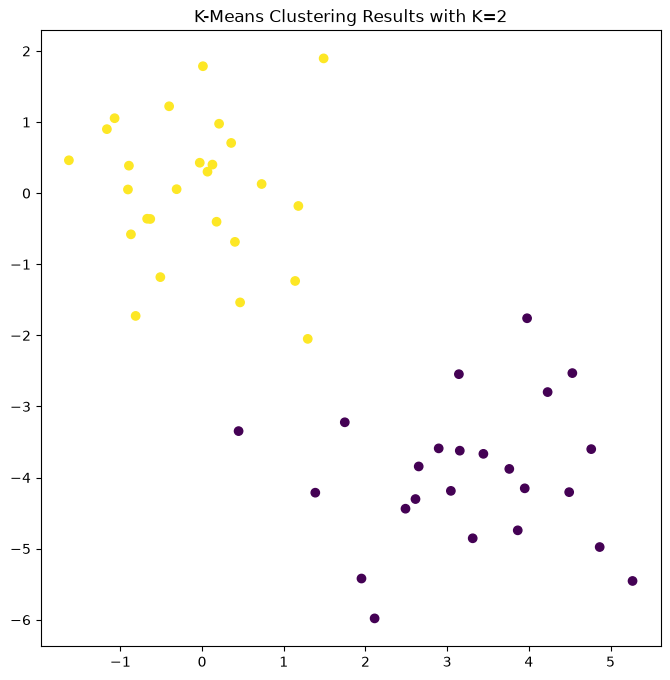

In [90]:
# Plot the observations and color them according to their K-Means cluster assignments.
fig , ax = plt.subplots (1, 1, figsize =(8 ,8))
ax.scatter(X[:,0], X[:,1], c=kmeans.labels_)
ax.set_title("K-Means Clustering Results with K=2");

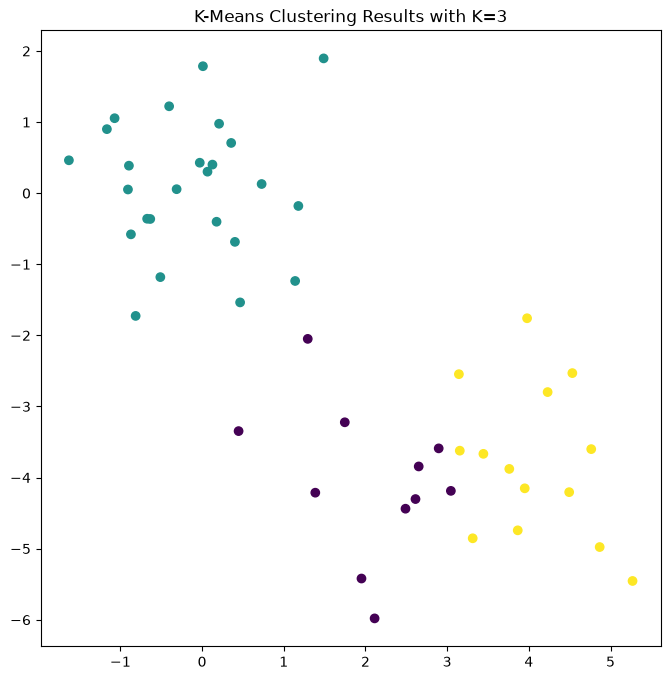

In [92]:
# Fit K-Means with three clusters and visualize the resulting three-cluster solution.
kmeans = KMeans(n_clusters =3,
random_state =3,
n_init =20).fit(X)
fig , ax = plt.subplots(figsize =(8 ,8))
ax.scatter(X[:,0], X[:,1], c=kmeans.labels_)
ax.set_title("K-Means Clustering Results with K=3");

In [94]:
# Compare K-Means solutions using different numbers of random initializations to examine sensitivity to initialization.
kmeans1 = KMeans(n_clusters =3,
random_state =3,
n_init =1).fit(X)
kmeans20 = KMeans(n_clusters =3,
random_state =3,
n_init =20).fit(X);
kmeans1.inertia_ , kmeans20.inertia_

(76.85131986999252, 75.06261242745384)

## Hierarchical Clustering

In [99]:
# Perform complete-linkage hierarchical clustering while retaining the full hierarchy.
HClust = AgglomerativeClustering
hc_comp = HClust( distance_threshold =0,
n_clusters=None ,
linkage='complete')
hc_comp.fit(X)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",None
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'complete'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",0
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False
Name,Type,Value
"children_ children_: array-like of shape (n_samples-1, 2)The children of each non-leaf node. Values less than `n_samples`correspond to leaves of the tree which are the original samples.A node `i` greater than or equal to `n_s

In [101]:
# Perform average-linkage hierarchical clustering while retaining the full hierarchy.
hc_avg = HClust( distance_threshold =0,
n_clusters=None ,
linkage='average');
hc_avg.fit(X)
hc_sing = HClust( distance_threshold =0,
n_clusters=None ,
linkage='single');
hc_sing.fit(X);

In [105]:
# Construct a distance matrix containing pairwise Euclidean distances between observations.
D = np.zeros ((X.shape [0], X.shape [0]));
for i in range(X.shape [0]):
    x_ = np.multiply.outer(np.ones(X.shape [0]) , X[i])
D[i] = np.sqrt(np.sum((X - x_)**2, 1));
hc_sing_pre = HClust( distance_threshold =0,
n_clusters=None ,
metric='precomputed',
linkage='single')
hc_sing_pre.fit(D)


,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",None
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'precomputed'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'single'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",0
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False
Name,Type,Value
"children_ children_: array-like of shape (n_samples-1, 2)The children of each non-leaf node. Values less than `n_samples`correspond to leaves of the tree which are the original samples.A node `i` greater than or equal to `n_s

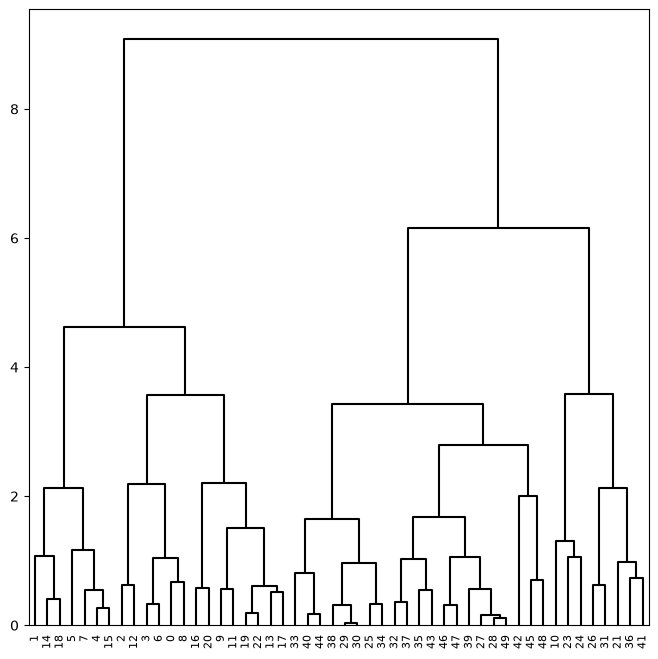

In [107]:
# Prepare dendrogram display settings and calculate the linkage matrix for complete-linkage clustering.
cargs = {'color_threshold':-np.inf ,
'above_threshold_color':'black'}
linkage_comp = compute_linkage(hc_comp)
fig , ax = plt.subplots (1, 1, figsize =(8, 8))
dendrogram(linkage_comp ,
ax=ax ,
** cargs);

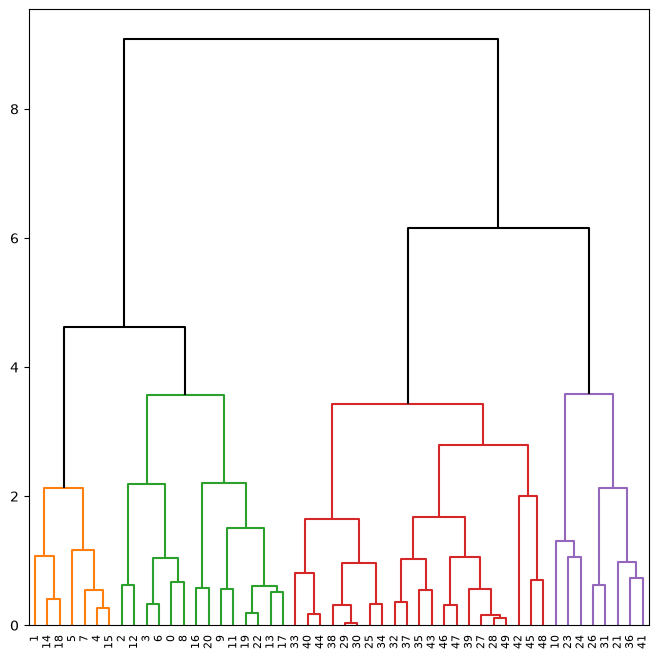

In [109]:
# Plot the hierarchical clustering dendrogram using the complete-linkage results.
fig , ax = plt.subplots (1, 1, figsize =(8, 8))
dendrogram(linkage_comp ,
ax=ax ,
color_threshold =4,
above_threshold_color ='black');

In [111]:
# Cut the hierarchical clustering tree to create four clusters and display the cluster assignments.
cut_tree(linkage_comp , n_clusters =4).T

array([[0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 2, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 2,
        0, 2, 2, 3, 2, 3, 3, 3, 3, 2, 3, 3, 3, 3, 2, 3, 3, 3, 3, 2, 3, 3,
        3, 3, 3, 3, 3, 3]])

In [113]:
# Cut the hierarchical clustering tree at a specified height and display the resulting cluster assignments.
cut_tree(linkage_comp , height =5)

array([[0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [1],
       [2],
       [1],
       [2],
       [2],
       [2],
       [2],
       [1],
       [2],
       [2],
       [2],
       [2],
       [1],
       [2],
       [2],
       [2],
       [2],
       [1],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2],
       [2]])

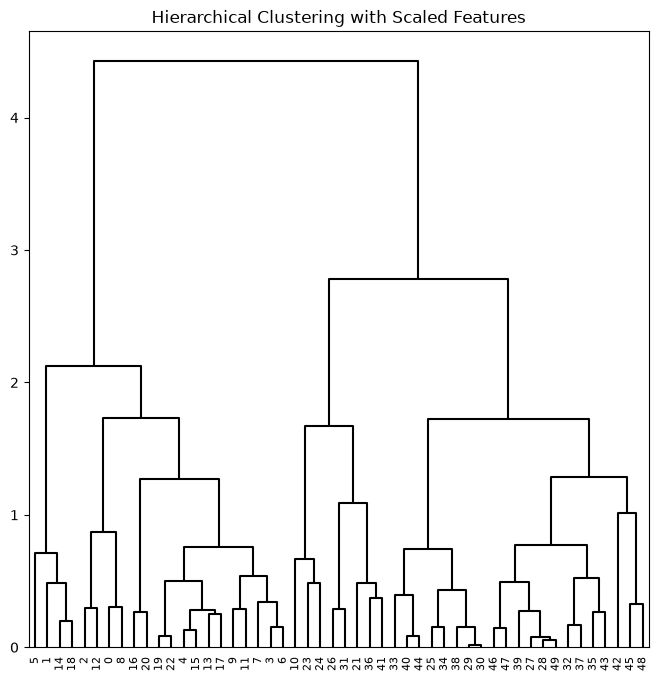

In [117]:
# Standardize the variables and repeat hierarchical clustering to examine the effect of scaling.
scaler = StandardScaler ()
X_scale = scaler.fit_transform(X)
hc_comp_scale = HClust( distance_threshold =0,
n_clusters=None ,
linkage='complete').fit(X_scale)
linkage_comp_scale = compute_linkage(hc_comp_scale)
fig , ax = plt.subplots (1, 1, figsize =(8, 8))
dendrogram(linkage_comp_scale , ax=ax , ** cargs)
ax.set_title("Hierarchical Clustering with Scaled Features");

## Unsupervised Learning

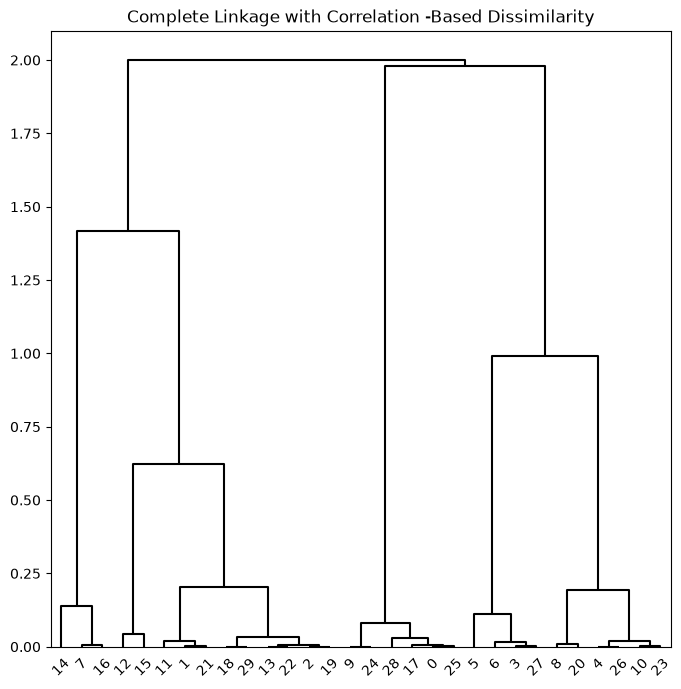

In [122]:
# Generate three-dimensional random data, build a correlation-based distance matrix, and perform hierarchical clustering.
X = np.random.standard_normal ((30, 3))
corD = 1 - np.corrcoef(X)
hc_cor = HClust(linkage='complete',
distance_threshold =0,
n_clusters=None ,
metric='precomputed')
hc_cor.fit(corD)
linkage_cor = compute_linkage(hc_cor)
fig , ax = plt.subplots (1, 1, figsize =(8, 8))
dendrogram(linkage_cor , ax=ax , ** cargs)
ax.set_title("Complete Linkage with Correlation -Based Dissimilarity");